In [48]:
import pandas as pd
import random
import matplotlib.pyplot as plt
import seaborn as sns
# Generate binary data
data = {'data1': [], 'data2': [], 'output': []}

for i in range(100):  # 100 samples
    data1_value = random.uniform(0, 1)  # Random value between 0 and 1 for data1
    data2_value = random.uniform(0, 1)  # Random value between 0 and 1 for data2
    
    # Create a binary output: if the sum of data1 and data2 is greater than 1, output is 1; else 0
    output_value = 1 if (data1_value + data2_value) > 1 else 0
    
    # Append values to the dictionary
    data['data1'].append(data1_value)
    data['data2'].append(data2_value)
    data['output'].append(output_value)

# Convert dictionary to DataFrame
df = pd.DataFrame(data)

# Display the first few rows
print(df.head())


      data1     data2  output
0  0.666937  0.795774       1
1  0.486622  0.928351       1
2  0.060040  0.388884       0
3  0.768618  0.276903       1
4  0.882153  0.125798       1


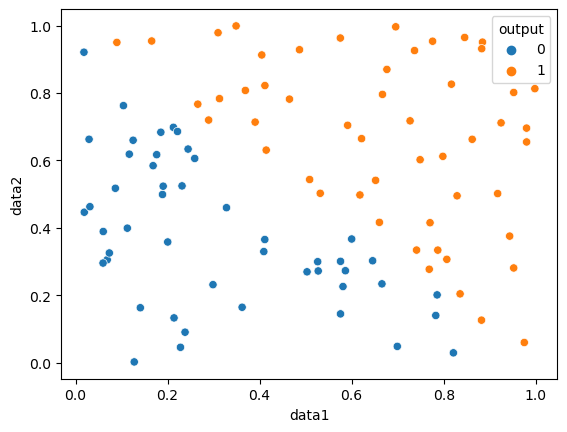

In [49]:
sns.scatterplot(x="data1",y="data2",data=df,hue="output")
plt.show()

In [50]:
x=df[["data1","data2"]]
y=df[["output"]]


In [51]:
from sklearn.preprocessing import PolynomialFeatures
pf=PolynomialFeatures(degree=2)
x=pd.DataFrame(pf.fit_transform(x))
x.head()

,0,1,2,3,4,5
0,1.0,0.666937,0.795774,0.444805,0.530731,0.633257
1,1.0,0.486622,0.928351,0.236801,0.451756,0.861836
2,1.0,0.060040,0.388884,0.003605,0.023349,0.151231
3,1.0,0.768618,0.276903,0.590774,0.212833,0.076675
4,1.0,0.882153,0.125798,0.778193,0.110973,0.015825


In [52]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
x_train.head(),y_train.head()

(      0         1         2         3         4         5
 55  1.0  0.845596  0.964743  0.715033  0.815783  0.930730
 88  1.0  0.368954  0.807519  0.136127  0.297937  0.652086
 26  1.0  0.018848  0.446168  0.000355  0.008409  0.199066
 42  1.0  0.018109  0.920958  0.000328  0.016678  0.848164
 69  1.0  0.124973  0.659694  0.015618  0.082444  0.435196,
     output
 55       1
 88       1
 26       0
 42       0
 69       0)

In [53]:
from sklearn.linear_model import LogisticRegression

In [54]:
lr=LogisticRegression()
lr.fit(x_train,y_train)

C:\Users\Suchana\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [55]:
lr.score(x_test,y_test)*100

95.0

In [56]:
lr.predict([[0.725826,0.412133]])

ValueError: X has 2 features, but LogisticRegression is expecting 6 features as input.